# kev-4b: base vs fine-tuneado

Todo sale de `kev_results/`:

- `fine_tuned/results/`: config y métricas del entrenamiento.
- `base-eval/<split>/` y `fine_tuned/eval/<split>/`: el mismo eval con los dos modelos sobre `train`, `val` y `test`.

En `rows.json`, `label` es el **índice** en `keys` (`1..5, N/A`), no el puntaje. Las reseñas de más de 384 tokens se rechazan, y son las mismas en los dos modelos.

**Ojo con `train`:** el fine-tuneado se entrenó con esas reseñas, así que ahí sus números son optimistas. La comparación que vale es `val` y `test`; la distancia entre `train` y `test` muestra cuánto memorizó.

In [ ]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
PALETTE = {"base": "#9aa5b1", "fine-tuned": "#2a7de1"}

ROOT = Path.cwd().parents[1]  # el notebook vive en notebooks/07_kev_eval/
RESULTS = ROOT / "kev_results"
EVAL_DIRS = {"base": RESULTS / "base-eval", "fine-tuned": RESULTS / "fine_tuned" / "eval"}
SPLITS = ["train", "val", "test"]
ASPECTS = ["food", "wait_time", "service", "price", "experience"]

## 1. Entrenamiento

In [ ]:
args = json.loads((RESULTS / "fine_tuned" / "results" / "training_config.json").read_text())["args"]
metrics = json.loads((RESULTS / "fine_tuned" / "results" / "training_metrics.json").read_text())
grad = metrics["grad_norm"]

pd.Series({
    "parte de": args["init_from"],
    "pesos": f"LoRA rango {args['lora']} (head congelado)" if args["head_lr"] == 0 else f"LoRA rango {args['lora']}",
    "épocas": args["epochs"],
    "learning rate": args["lr"],
    "reseñas por época": metrics["records_seen"] // args["epochs"],
    "duración": f"{metrics['wall_seconds'] / 60:.0f} min en {metrics['device']}",
    "norma del gradiente por época": " -> ".join(f"{g['mean']:.2f}" for g in grad),
}, name="").to_frame()

,
parte de,jaredpalmer/kev-4b
pesos,LoRA rango 16 (head congelado)
épocas,2
learning rate,0.00002
reseñas por época,1442
duración,61 min en cuda
norma del gradiente por época,4.43 -> 3.86


No se guardó la loss; la norma del gradiente baja entre épocas. La pérdida ordinal estaba apagada (`ord_w` 0): errar por 1 punto costó lo mismo que errar por 4.

## 2. Base vs fine-tuneado

Una fila por pregunta (reseña × aspecto), con la predicción (la opción más probable) y su confianza.

In [ ]:
def load_rows(model, split):
    rows = json.loads((EVAL_DIRS[model] / split / "rows.json").read_text())
    keys = rows[0]["keys"]
    p = np.array([r["p"] for r in rows])
    label = np.array([r["label"] for r in rows])
    return pd.DataFrame({
        "model": model,
        "split": split,
        "id": [r["id"] for r in rows],
        "aspect": [r["question"] for r in rows],
        "label": [keys[i] for i in label],
        "pred": [keys[i] for i in p.argmax(axis=1)],
        "conf": p.max(axis=1),
        "p_label": p[np.arange(len(rows)), label],
    })

df = pd.concat([load_rows(m, s) for m in EVAL_DIRS for s in SPLITS], ignore_index=True)
df["correct"] = df["label"] == df["pred"]
df["rated"] = df["label"] != "N/A"  # la etiqueta humana tiene puntaje

# mismas reseñas en los dos modelos, si no la comparación no vale
for split in SPLITS:
    ids = [set(df.query("model == @m and split == @split")["id"]) for m in EVAL_DIRS]
    assert ids[0] == ids[1], split

df.groupby(["split", "model"], sort=False).size().unstack().loc[SPLITS]

model,base,fine-tuned
split,,
train,7210,7210
val,1530,1530
test,1535,1535


### Métricas principales

- **NLL**: calidad de las probabilidades, menor es mejor.
- **Accuracy con puntaje**: exacto, solo preguntas con etiqueta 1–5. La accuracy total está inflada por los N/A (casi la mitad de las etiquetas).
- **Cobertura al 95%**: qué fracción de respuestas se puede aceptar sola, de la más a la menos confiada, manteniendo ~95% de accuracy.

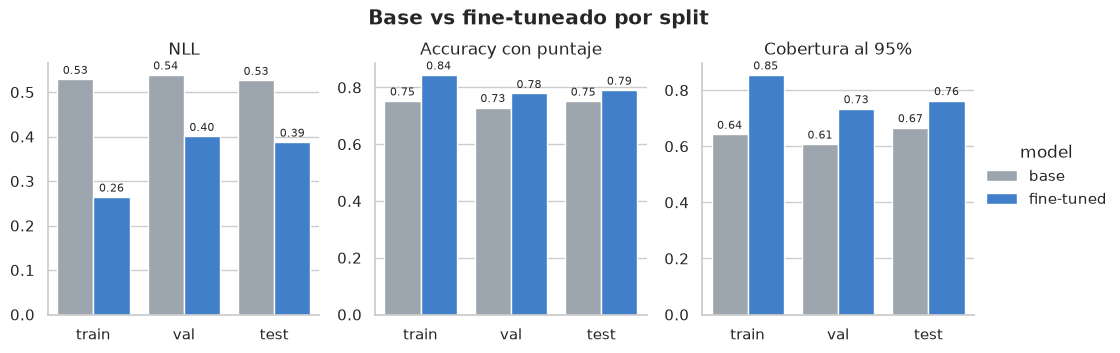

In [ ]:
def summarize(g):
    report = json.loads((EVAL_DIRS[g.name[0]] / g.name[1] / "report.json").read_text())["clean"]
    return pd.Series({
        "NLL": report["nll"],
        "Accuracy con puntaje": g.loc[g["rated"], "correct"].mean(),
        "Cobertura al 95%": report["coverage_at_5pct_error"],
    })

summary = df.groupby(["model", "split"]).apply(summarize).reset_index()
long = summary.melt(id_vars=["model", "split"], var_name="metric")

g = sns.catplot(data=long, kind="bar", x="split", y="value", hue="model", col="metric",
                order=SPLITS, palette=PALETTE, sharey=False, height=3.6, aspect=0.95)
g.set_titles("{col_name}").set_axis_labels("", "")
for ax in g.axes.flat:
    for container in ax.containers:
        ax.bar_label(container, fmt="%.2f", fontsize=8, padding=2)
g.fig.suptitle("Base vs fine-tuneado por split", y=1.04, fontweight="bold");

In [ ]:
summary.pivot(index="split", columns="model").loc[SPLITS].round(3)

NLL            Accuracy con puntaje            Cobertura al 95%  \
model   base fine-tuned                 base fine-tuned             base   
split                                                                      
train  0.529      0.264                0.753      0.844            0.643   
val    0.539      0.401                0.729      0.779            0.608   
test   0.527      0.388                0.752      0.790            0.666   

                  
model fine-tuned  
split             
train      0.855  
val        0.734  
test       0.763

### Por aspecto (test)

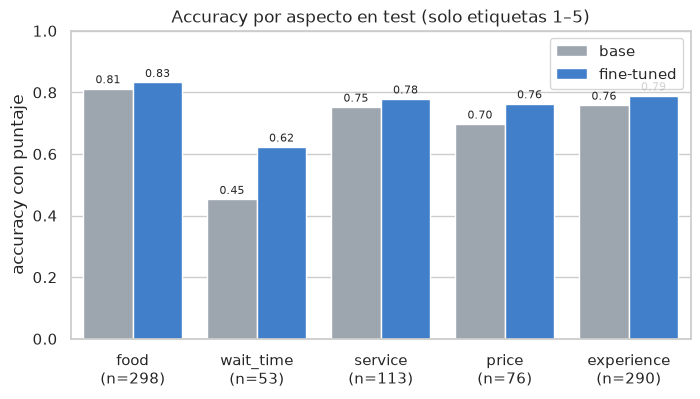

In [ ]:
test = df[df["split"] == "test"]
per_aspect = (test[test["rated"]].groupby(["model", "aspect"])["correct"].mean().rename("accuracy").reset_index())
counts = test[test["rated"]].groupby("aspect").size() // 2

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=per_aspect, x="aspect", y="accuracy", hue="model", order=ASPECTS, palette=PALETTE, ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", fontsize=8, padding=2)
ax.set_xticks(range(len(ASPECTS)), [f"{a}\n(n={counts[a]})" for a in ASPECTS])
ax.set(xlabel="", ylabel="accuracy con puntaje", ylim=(0, 1), title="Accuracy por aspecto en test (solo etiquetas 1–5)")
ax.legend(title="");

`n` es cuántas preguntas de test tienen etiqueta 1–5: los aspectos con pocos ejemplos (`wait_time`, `price`) son los más ruidosos.

### Matrices de confusión (test)

Cada fila suma 1: de las reseñas con esa etiqueta humana, qué fracción recibió cada predicción. Lo ideal es la diagonal.

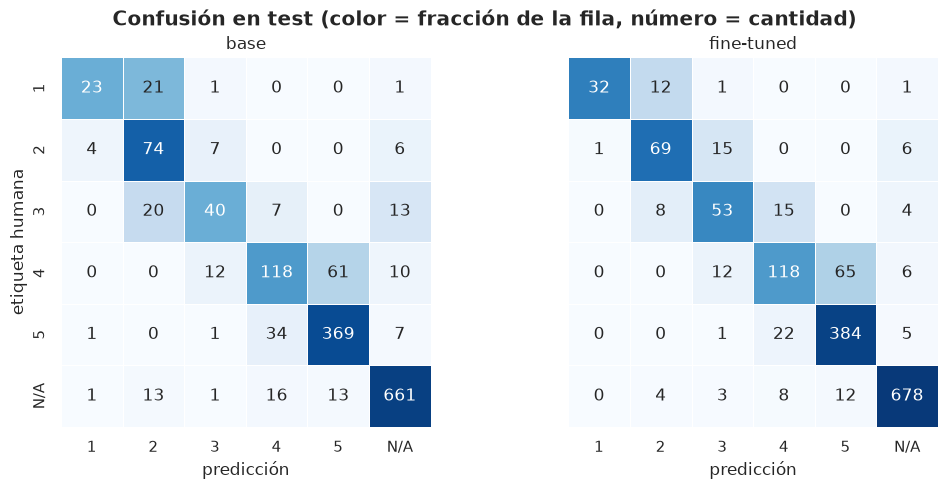

In [ ]:
keys = ["1", "2", "3", "4", "5", "N/A"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
for ax, model in zip(axes, EVAL_DIRS):
    t = test[test["model"] == model]
    cm = pd.crosstab(t["label"], t["pred"]).reindex(index=keys, columns=keys, fill_value=0)
    sns.heatmap(cm.div(cm.sum(axis=1), axis=0), annot=cm, fmt="d", cmap="Blues", vmin=0, vmax=1,
                cbar=False, square=True, linewidths=0.5, ax=ax)
    ax.set(title=model, xlabel="predicción", ylabel="etiqueta humana" if ax is axes[0] else "")
fig.suptitle("Confusión en test (color = fracción de la fila, número = cantidad)", fontweight="bold");

### Overfitting?

In [ ]:
ft = summary[summary["model"] == "fine-tuned"].set_index("split").loc[SPLITS]
ft[["NLL", "Accuracy con puntaje"]].round(3)

,NLL,Accuracy con puntaje
split,,
train,0.264,0.844
val,0.401,0.779
test,0.388,0.790


Train mejora bastante más que test (NLL 0.26 vs 0.39): 

memorizo algo, pero val y test igual mejoran contra el base.